# RoadVision AI — YOLO Baseline Training

Train a first YOLO object-detection baseline using the prepared dataset from `04_dataset_preparation.ipynb`. Do not modify or train from the original `trafic_data/` source.

Baseline: pretrained YOLOv8n, image size 640, 30 epochs, batch size 16, seed 42. These are starting settings, not optimized hyperparameters.


## 1. Install and import dependencies
Uncomment the install line only if Ultralytics is not installed.

In [1]:
# %pip install -q ultralytics

In [2]:
from pathlib import Path
import os, random, platform, yaml
import numpy as np
import pandas as pd
from IPython.display import display, Image as IPImage
import matplotlib.pyplot as plt
import torch, ultralytics
from ultralytics import YOLO

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))

Python: 3.10.22
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.193
CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


## 2. Configure the prepared dataset

In [3]:
DEFAULT_ROOT = (Path.home() / ".cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned")
CLEAN_ROOT = Path(os.getenv("ROADVISION_CLEANED_ROOT", str(DEFAULT_ROOT))).expanduser().resolve()
print("Prepared dataset:", CLEAN_ROOT)
if not CLEAN_ROOT.is_dir():
    raise FileNotFoundError(f"Prepared dataset not found: {CLEAN_ROOT}. Set ROADVISION_CLEANED_ROOT to its actual location.")
SPLITS = {s: CLEAN_ROOT / s for s in ("train", "valid", "test")}

def get_images(folder):
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
    return sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in exts)

for split in ("train", "valid"):
    for part in ("images", "labels"):
        p = SPLITS[split] / part
        if not p.is_dir(): raise FileNotFoundError(f"Missing required directory: {p}")
for split, folder in SPLITS.items():
    image_dir = folder / "images"
    print(f"{split}: {len(get_images(image_dir)):,} images" if image_dir.is_dir() else f"{split}: not present (optional)")

Prepared dataset: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned
train: 2,703 images
valid: 300 images
test: not present (optional)


## 3. Verify class names
Class order must match class IDs in the YOLO label files.

In [4]:
CLASS_NAMES = [
    "ambulance", "army vehicle", "auto rickshaw", "bicycle", "bus",
    "car", "garbagevan", "human hauler", "minibus", "minivan",
    "motorbike", "pickup", "policecar", "rickshaw", "scooter",
    "suv", "taxi", "three wheelers -CNG-", "truck", "van", "wheelbarrow",
]
NC = len(CLASS_NAMES)
assert NC == 21, f"Expected 21 classes, got {NC}"
for i, name in enumerate(CLASS_NAMES): print(f"{i:2}: {name}")

 0: ambulance
 1: army vehicle
 2: auto rickshaw
 3: bicycle
 4: bus
 5: car
 6: garbagevan
 7: human hauler
 8: minibus
 9: minivan
10: motorbike
11: pickup
12: policecar
13: rickshaw
14: scooter
15: suv
16: taxi
17: three wheelers -CNG-
18: truck
19: van
20: wheelbarrow


## 4. Load the prepared YOLO dataset YAML

Reuses `roadvision_prepared.yaml` from notebook 04 (single source of truth) and checks its classes against `CLASS_NAMES`. Labels are not rewritten.

In [5]:
DATA_YAML = CLEAN_ROOT / "roadvision_prepared.yaml"  # produced by 04_dataset_preparation.ipynb
if not DATA_YAML.is_file():
    raise FileNotFoundError(f"{DATA_YAML} not found. Run 04_dataset_preparation.ipynb first.")
with DATA_YAML.open(encoding="utf-8") as f:
    data_config = yaml.safe_load(f)
names = data_config["names"]
names = [names[k] for k in sorted(names, key=int)] if isinstance(names, dict) else list(names)
assert int(data_config["nc"]) == NC and names == CLASS_NAMES, "YAML classes differ from CLASS_NAMES"
print(DATA_YAML.read_text(encoding="utf-8"))

path: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned
train: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/train/images
val: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/valid/images
nc: 21
names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow



## 5. Configure the run
Defaults reproduce the baseline: YOLOv8n, imgsz 640, 30 epochs, batch 16, patience 10, seed 42. If GPU memory is insufficient, reduce batch size to 8 or 4.

Controlled comparisons use the same notebook with the same split, seed, batch and augmentation. Only these env vars change (set before launching Jupyter):
- Control: `RV_EPOCHS=100 RV_PATIENCE=20`
- YOLOv9-C: `RV_WEIGHTS=yolov9c.pt RV_EPOCHS=100 RV_PATIENCE=20`
- Resolution test: `RV_IMGSZ=960`

In [6]:
MODEL_WEIGHTS = os.getenv("RV_WEIGHTS", "yolov8n.pt")
IMG_SIZE = int(os.getenv("RV_IMGSZ", 640))
EPOCHS = int(os.getenv("RV_EPOCHS", 30))
BATCH_SIZE = 16
PATIENCE = int(os.getenv("RV_PATIENCE", 10))
WORKERS = 2
DEVICE = 0 if torch.cuda.is_available() else "cpu"
RUNS_DIR = CLEAN_ROOT / "training_runs"
_default_name = "yolov8n_baseline" if (MODEL_WEIGHTS, EPOCHS, IMG_SIZE) == ("yolov8n.pt", 30, 640) else f"{Path(MODEL_WEIGHTS).stem}_ep{EPOCHS}_img{IMG_SIZE}"
RUN_NAME = os.getenv("RV_RUN_NAME", _default_name)
print({"weights": MODEL_WEIGHTS, "imgsz": IMG_SIZE, "epochs": EPOCHS, "batch": BATCH_SIZE, "patience": PATIENCE, "device": DEVICE, "seed": SEED, "run": RUN_NAME})

{'weights': 'yolov8n.pt', 'imgsz': 640, 'epochs': 30, 'batch': 16, 'patience': 10, 'device': 0, 'seed': 42, 'run': 'yolov8n_baseline'}


## 6. Train the baseline model
Training may take time. Keep the logs and artifacts generated by this run.

In [7]:
model = YOLO(MODEL_WEIGHTS)
train_results = model.train(
    data=str(DATA_YAML), imgsz=IMG_SIZE, epochs=EPOCHS, batch=BATCH_SIZE,
    patience=PATIENCE, workers=WORKERS, device=DEVICE, seed=SEED,
    deterministic=True, pretrained=True, project=str(RUNS_DIR), name=RUN_NAME,
    exist_ok=True, plots=True, save=True, verbose=True,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"
print("Run directory:", RUN_DIR)
print("Best checkpoint:", BEST_WEIGHTS, BEST_WEIGHTS.is_file())
print("Last checkpoint:", LAST_WEIGHTS, LAST_WEIGHTS.is_file())

Ultralytics 8.4.193 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 11913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/roadvision_prepared.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

## 7. Evaluate on validation data

- **Precision:** fraction of predicted objects that are correct.
- **Recall:** fraction of annotated objects detected.
- **mAP@50:** mean average precision at IoU 0.50.
- **mAP@50–95:** mean average precision averaged over IoU thresholds 0.50 to 0.95.

Use validation results for development. Do not repeatedly tune against the test split.

In [8]:
if not BEST_WEIGHTS.is_file(): raise FileNotFoundError(f"Best checkpoint not found: {BEST_WEIGHTS}")
best_model = YOLO(str(BEST_WEIGHTS))
val_metrics = best_model.val(data=str(DATA_YAML), split="val", imgsz=IMG_SIZE, batch=BATCH_SIZE, device=DEVICE, workers=WORKERS, plots=True, project=str(RUNS_DIR), name=f"{RUN_NAME}_validation", exist_ok=True)
for name, value in getattr(val_metrics, "results_dict", {}).items():
    try: print(f"{name}: {float(value):.4f}")
    except (TypeError, ValueError): print(f"{name}: {value}")

Ultralytics 8.4.193 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 11913MiB)
Model summary (fused): 73 layers, 3,137,567 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 484.1±139.5 MB/s, size: 32.9 KB)
val: Scanning /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/valid/labels.cache... 300 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 34.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 4.3it/s 4.4s0.1s
                   all        300       2560      0.691      0.383      0.436      0.269
               bicycle         30         32      0.654        0.5      0.523       0.22
                   bus        218        423      0.838      0.514      0.672      0.437
                   car        232        842      0.802      0.677      0.767      0.504
               minibus 

,class_id,class,train_instances,val_instances,P,R,mAP50,mAP50-95,evaluable
12,12,policecar,31,1,1.000000,0.000000,0.000000,0.000000,False
14,14,scooter,37,1,1.000000,0.000000,0.004383,0.000438,False
20,20,wheelbarrow,111,8,1.000000,0.000000,0.086730,0.052438,False
19,19,van,693,62,0.201246,0.211336,0.215070,0.132305,True
15,15,suv,798,59,0.325855,0.305085,0.231134,0.160713,True
11,11,pickup,1081,142,0.658198,0.244129,0.369254,0.209510,True
9,9,minivan,822,109,0.524217,0.363923,0.374796,0.262835,True
10,10,motorbike,1948,335,0.640340,0.462687,0.494405,0.160295,True
8,8,minibus,93,2,0.334621,0.500000,0.495000,0.445500,False
3,3,bicycle,427,32,0.654234,0.500000,0.523347,0.219976,True


Macro over 11 classes with >= 20 val instances: mAP50=0.5127 | mAP50-95=0.3055
Absent from val: ['ambulance', 'army vehicle', 'auto rickshaw', 'garbagevan', 'human hauler']
Not evaluable (<20 val instances): ['minibus', 'policecar', 'scooter', 'taxi', 'wheelbarrow']


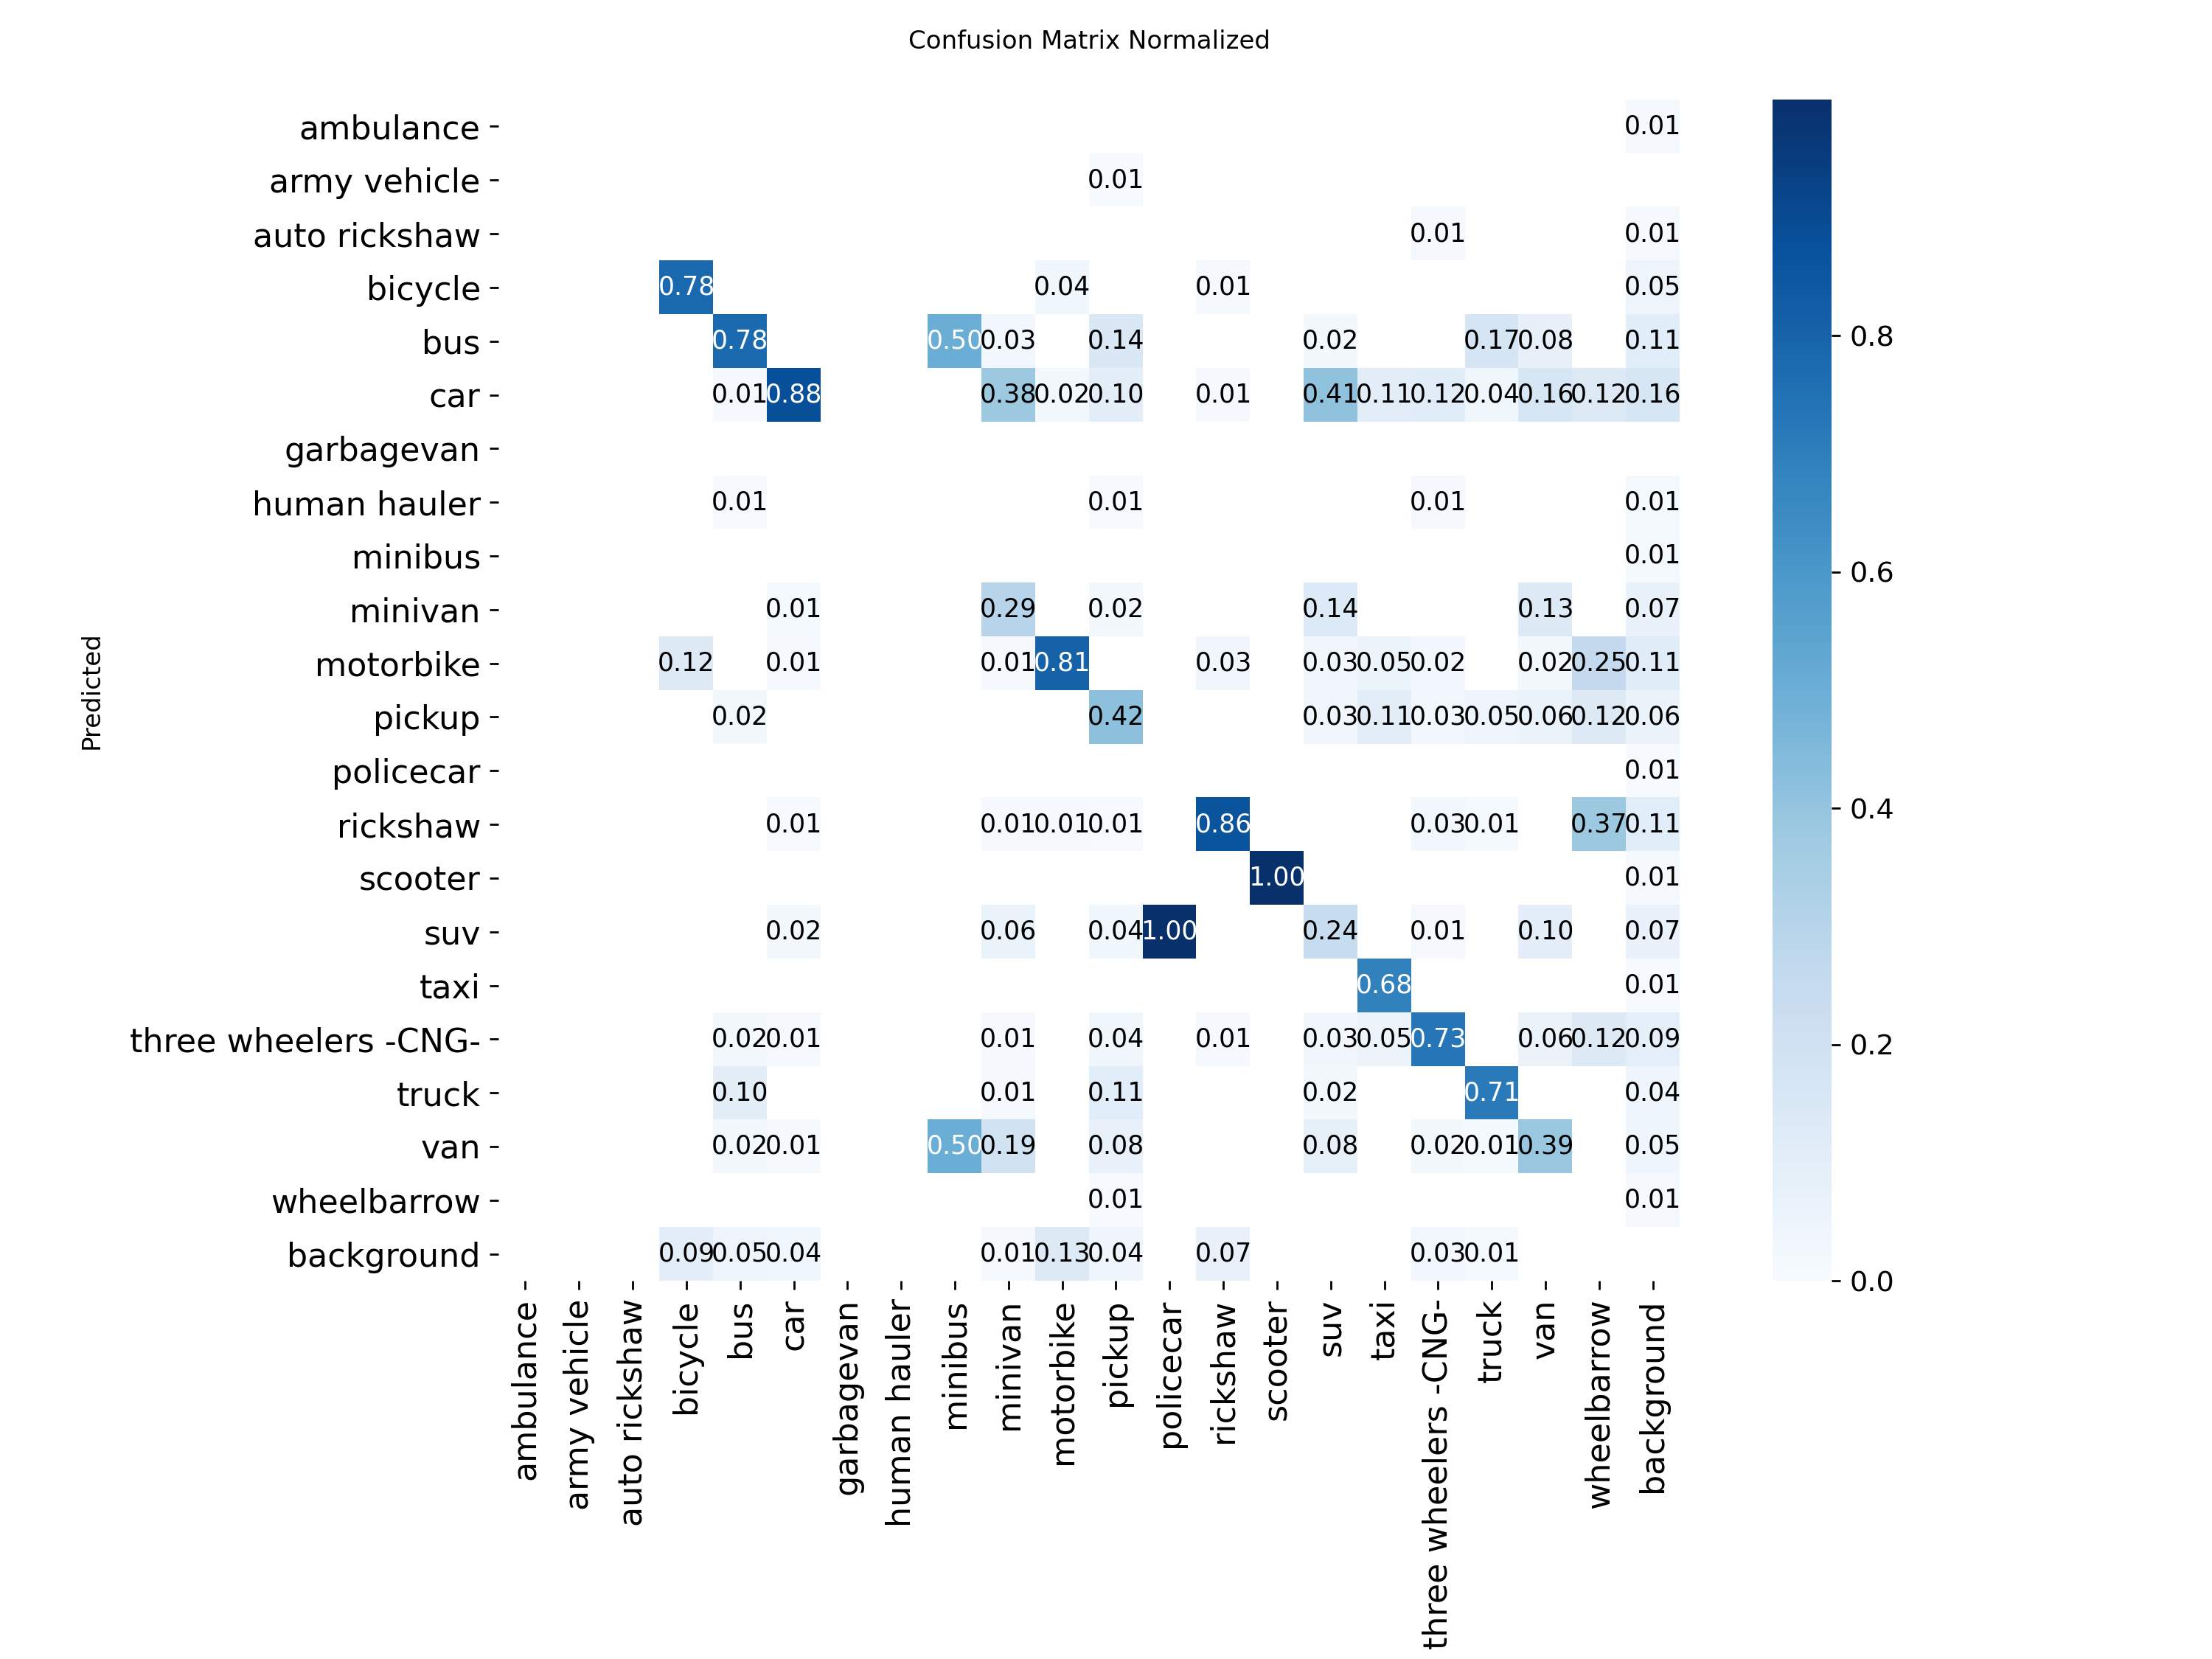

In [9]:
MIN_EVAL_INSTANCES = 20  # classes with fewer val instances give statistically meaningless AP

def count_instances(label_dir, nc):
    counts = np.zeros(nc, dtype=int)
    for f in Path(label_dir).glob("*.txt"):
        for line in f.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) == 5: counts[int(float(parts[0]))] += 1
    return counts

box = val_metrics.box
per_class = pd.DataFrame({
    "class_id": range(NC), "class": CLASS_NAMES,
    "train_instances": count_instances(SPLITS["train"] / "labels", NC),
    "val_instances": count_instances(SPLITS["valid"] / "labels", NC),
    "P": np.nan, "R": np.nan, "mAP50": np.nan, "mAP50-95": np.nan,
})
for k, cid in enumerate(box.ap_class_index):
    p, r, ap50, ap = box.class_result(k)
    per_class.loc[per_class.class_id == int(cid), ["P", "R", "mAP50", "mAP50-95"]] = [p, r, ap50, ap]
per_class["evaluable"] = per_class["val_instances"] >= MIN_EVAL_INSTANCES
display(per_class.sort_values("mAP50"))

ev = per_class[per_class["evaluable"]]
macro = {"classes": int(len(ev)), "mAP50": float(ev["mAP50"].mean()), "mAP50-95": float(ev["mAP50-95"].mean())}
print(f"Macro over {macro['classes']} classes with >= {MIN_EVAL_INSTANCES} val instances: mAP50={macro['mAP50']:.4f} | mAP50-95={macro['mAP50-95']:.4f}")
print("Absent from val:", per_class.loc[per_class.val_instances == 0, "class"].tolist())
print(f"Not evaluable (<{MIN_EVAL_INSTANCES} val instances):", per_class.loc[(per_class.val_instances > 0) & ~per_class.evaluable, "class"].tolist())

VAL_DIR = Path(val_metrics.save_dir)
per_class.to_csv(VAL_DIR / "per_class_metrics.csv", index=False)
cm_path = VAL_DIR / "confusion_matrix_normalized.png"
if cm_path.is_file(): display(IPImage(filename=str(cm_path)))
else: print("Confusion matrix not found:", cm_path)

## 8. Inspect training history and artifacts

Best epoch (mAP50-95): 29 of 30 | mAP50-95=0.2686


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,582.315,1.16767,0.94740,1.01710,0.58079,0.40671,0.42021,0.25326,1.32087,1.19295,1.10374,0.000070,0.000070,0.000070
26,27,604.764,1.16771,0.93756,1.01850,0.60517,0.41508,0.40615,0.24415,1.33415,1.19087,1.10753,0.000057,0.000057,0.000057
27,28,626.833,1.15921,0.92286,1.01526,0.61687,0.42949,0.43904,0.26719,1.33565,1.19657,1.10501,0.000044,0.000044,0.000044
28,29,649.248,1.15240,0.91029,1.01072,0.69118,0.38390,0.43741,0.26864,1.34127,1.18866,1.10799,0.000030,0.000030,0.000030
29,30,670.635,1.15026,0.90632,1.00887,0.65684,0.41338,0.41920,0.24904,1.34102,1.17809,1.10757,0.000017,0.000017,0.000017


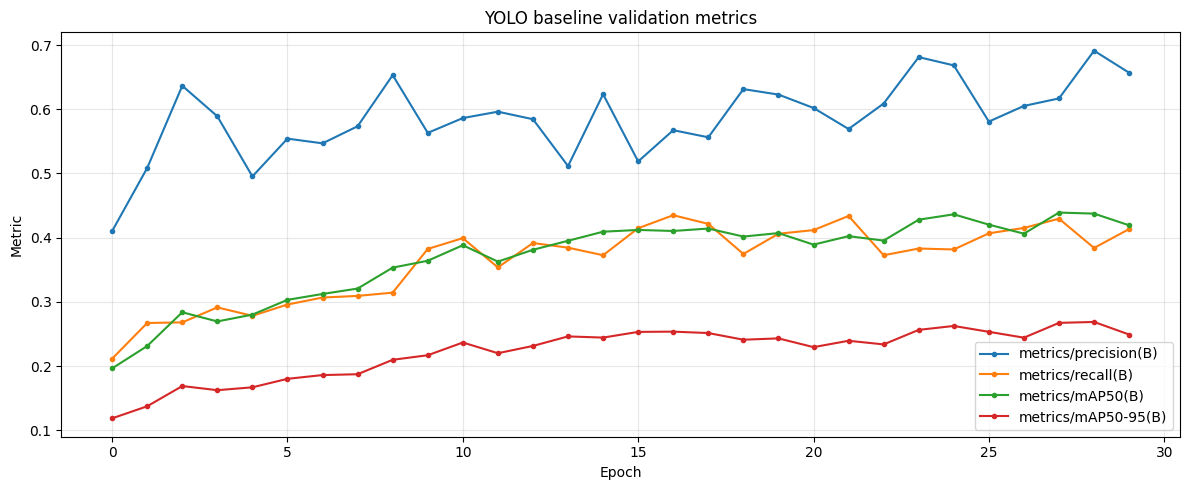

Run artifacts:
- BoxF1_curve.png
- BoxPR_curve.png
- BoxP_curve.png
- BoxR_curve.png
- args.yaml
- confusion_matrix.png
- confusion_matrix_normalized.png
- labels.jpg
- results.csv
- results.png
- train_batch0.jpg
- train_batch1.jpg
- train_batch2.jpg
- train_batch3380.jpg
- train_batch3381.jpg
- train_batch3382.jpg
- val_batch0_labels.jpg
- val_batch0_pred.jpg
- val_batch1_labels.jpg
- val_batch1_pred.jpg
- val_batch2_labels.jpg
- val_batch2_pred.jpg
- weights


In [10]:
results_csv = RUN_DIR / "results.csv"
if results_csv.is_file():
    history = pd.read_csv(results_csv)
    history.columns = history.columns.str.strip()
    best_i = history["metrics/mAP50-95(B)"].idxmax()
    print(f"Best epoch (mAP50-95): {int(history.loc[best_i, 'epoch'])} of {len(history)} | mAP50-95={history.loc[best_i, 'metrics/mAP50-95(B)']:.4f}")
    display(history.tail())
    metric_cols = [c for c in history.columns if any(k in c.lower() for k in ("precision", "recall", "map50"))]
    if metric_cols:
        ax = history[metric_cols].plot(figsize=(12, 5), marker=".")
        ax.set_title("YOLO baseline validation metrics")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Metric"); ax.grid(True, alpha=0.3)
        plt.tight_layout(); plt.show()
else: print("Training history CSV not found:", results_csv)
print("Run artifacts:")
for item in sorted(RUN_DIR.iterdir()): print("-", item.name)

## 9. Optional: evaluate on the test split once

Run only after model/configuration choices are complete and only if a genuine held-out test split exists. Do not copy validation data to create a test set.

In [11]:
if (CLEAN_ROOT / "test/images").is_dir():
    test_metrics = best_model.val(data=str(DATA_YAML), split="test", imgsz=IMG_SIZE, batch=BATCH_SIZE, device=DEVICE, workers=WORKERS, plots=True, project=str(RUNS_DIR), name=f"{RUN_NAME}_test", exist_ok=True)
    for name, value in getattr(test_metrics, "results_dict", {}).items():
        try: print(f"{name}: {float(value):.4f}")
        except (TypeError, ValueError): print(f"{name}: {value}")
else: print("No test split found. Test evaluation skipped.")

No test split found. Test evaluation skipped.


## 10. Experiment report

The cell below records actual results to `experiment_report.json` in the run directory. Add observations and the next experiment manually.

**Next step:** analyze the confusion matrix and per-class table, then run a controlled experiment. Keep the test split untouched until final evaluation.

In [12]:
import json
def n_images(split):
    d = SPLITS[split] / "images"
    return len(get_images(d)) if d.is_dir() else "not available"

rd = val_metrics.results_dict
report = {
    "dataset": str(CLEAN_ROOT), "data_yaml": str(DATA_YAML),
    "images": {s: n_images(s) for s in ("train", "valid", "test")},
    "model": MODEL_WEIGHTS, "imgsz": IMG_SIZE, "epochs": EPOCHS, "batch": BATCH_SIZE, "patience": PATIENCE, "seed": SEED,
    "val": {"precision": rd["metrics/precision(B)"], "recall": rd["metrics/recall(B)"], "mAP50": rd["metrics/mAP50(B)"], "mAP50-95": rd["metrics/mAP50-95(B)"]},
    "val_macro_evaluable_classes": macro,
    "best_checkpoint": str(BEST_WEIGHTS),
}
(RUN_DIR / "experiment_report.json").write_text(json.dumps(report, indent=2, default=float), encoding="utf-8")
print(json.dumps(report, indent=2, default=float))

{
  "dataset": "/root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned",
  "data_yaml": "/root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/roadvision_prepared.yaml",
  "images": {
    "train": 2703,
    "valid": 300,
    "test": "not available"
  },
  "model": "yolov8n.pt",
  "imgsz": 640,
  "epochs": 30,
  "batch": 16,
  "patience": 10,
  "seed": 42,
  "val": {
    "precision": 0.6905058961152799,
    "recall": 0.38343154837465915,
    "mAP50": 0.43557661473648535,
    "mAP50-95": 0.26853803527930165
  },
  "val_macro_evaluable_classes": {
    "classes": 11,
    "mAP50": 0.5127269100345457,
    "mAP50-95": 0.3055366760378156
  },
  "best_checkpoint": "/root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/training_runs/yolov8n_baseline/weights/best.pt"
}
